# Obligatorio 2 — Problema 1

Entrenamiento y comparación de modelos de regresión sobre datos sintéticos, y análisis del comportamiento de las predicciones cuando el conjunto de test sufre un **desplazamiento de la media** (*shift*). El PCA se usa como herramienta para detectar y visualizar ese desplazamiento.

Detalle del enunciado y de los pasos: [`../RESUME.md`](../RESUME.md).

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.linear_model import BayesianRidge, LinearRegression, RidgeCV
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## 0. Configuración

Todas las decisiones globales (semilla, tamaños, variables informativas y coeficientes) se fijan acá una sola vez.
Cambiar cualquiera de estos valores obliga a rehacer el pipeline completo.

In [10]:
SEED = 42
N = 150          # observaciones totales
P = 50           # variables
N_TRAIN = 100
N_TEST = 50
NOISE_VAR = 0.25 # varianza del ruido gaussiano (sigma = 0.5)

# Variables que realmente explican Y (las demás tienen coeficiente 0)
INFORMATIVAS = [3, 11, 24, 37, 45]
COEFICIENTES = [3.0, -2.0, 1.5, 2.5, -1.0]

print(f"N={N}  P={P}  train={N_TRAIN}  test={N_TEST}")
print("Variables informativas:", INFORMATIVAS)

N=150  P=50  train=100  test=50
Variables informativas: [3, 11, 24, 37, 45]


## 1. Datos sintéticos (150 × 50)

Se carga la matriz de covarianzas provista en el EVA y se generan los datos con una normal multivariada.

In [11]:
sigma = pd.read_csv("/mat_cov.csv").to_numpy() # hay que agregar la matriz de covarianza en el contexto del colab
columnas = [f"V{j + 1}" for j in range(P)]

assert sigma.shape == (P, P), sigma.shape
assert np.allclose(sigma, sigma.T), "la matriz debe ser simétrica"

autovalores = np.linalg.eigvalsh(sigma)
print("autovalor mínimo:", autovalores.min())
assert autovalores.min() > 0, "la matriz debe ser definida positiva"

rng = np.random.default_rng(SEED)
X = rng.multivariate_normal(mean=np.zeros(P), cov=sigma, size=N)
print("X:", X.shape)

autovalor mínimo: 1.1892988109161212e-07
X: (150, 50)


## 2. Variable objetivo

$Y = \sum_{j=1}^{50} \beta_j X_j + \varepsilon$, con solo **5 coeficientes no nulos** y
$\varepsilon \sim \mathcal{N}(0,\, 0.25)$.

In [12]:
beta_true = np.zeros(P)
beta_true[INFORMATIVAS] = COEFICIENTES

ruido = rng.normal(loc=0.0, scale=np.sqrt(NOISE_VAR), size=N)
y = X @ beta_true + ruido

var_senal = np.var(X @ beta_true)
print(f"varianza de la señal: {var_senal:.2f}")
print(f"varianza del ruido : {NOISE_VAR:.2f}")
print(f"R² teórico aprox.  : {var_senal / (var_senal + NOISE_VAR):.3f}")

varianza de la señal: 9.71
varianza del ruido : 0.25
R² teórico aprox.  : 0.975


## 3. Separación train / test

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=N_TRAIN, test_size=N_TEST, random_state=SEED
)
print("train:", X_train.shape, "| test:", X_test.shape)

train: (100, 50) | test: (50, 50)


## 4. Entrenamiento de los cuatro modelos

### 4.1 Escalado

Ridge y PCA no son invariantes a escala, así que se estandariza usando **solo** las medias y desvíos de train.

In [14]:
scaler = StandardScaler().fit(X_train)
X_train_std = scaler.transform(X_train)
X_test_std = scaler.transform(X_test)

# beta expresado en la escala estandarizada (para comparar con los coeficientes estimados)
beta_true_std = beta_true * scaler.scale_

### 4.2 Regresión lineal simple (OLS)

In [15]:
ols = LinearRegression().fit(X_train_std, y_train)
print(f"MSE train: {np.mean((y_train - ols.predict(X_train_std)) ** 2):.4f}")

MSE train: 0.1287


### 4.3 Regresión Ridge

El hiperparámetro $\alpha$ se elige por validación cruzada.

In [16]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

ridge = RidgeCV(alphas=np.logspace(-3, 3, 60), cv=cv).fit(X_train_std, y_train)
print(f"alpha elegido: {ridge.alpha_:.4g}")
print(f"MSE train   : {np.mean((y_train - ridge.predict(X_train_std)) ** 2):.4f}")

alpha elegido: 1.421
MSE train   : 0.1443


### 4.4 Regresión bayesiana

In [17]:
bayes = BayesianRidge().fit(X_train_std, y_train)
print(f"alpha={bayes.alpha_:.4g}  lambda={bayes.lambda_:.4g}")
print(f"MSE train: {np.mean((y_train - bayes.predict(X_train_std)) ** 2):.4f}")

alpha=4.027  lambda=4.61
MSE train: 0.1408


### 4.5 Regresión sobre componentes principales (PCR)

Se elige el número de componentes $k$ por validación cruzada. Luego se entrenan PCA y regresión lineal con ese $k$.

Los pesos de cada variable en el modelo se recuperan combinando los coeficientes sobre las componentes con los *loadings*:

$$\hat{\beta}_{\text{std}} = V_{:,1:k}\,\hat{\gamma}, \qquad \hat{\beta}_{\text{orig}} = \hat{\beta}_{\text{std}} \oslash s$$

donde $V$ son los autovectores (filas de `pca.components_`), $\hat{\gamma}$ los coeficientes de la regresión sobre los scores y $s$ los desvíos estándar usados al escalar.

In [18]:
pcr_pipeline = make_pipeline(PCA(), LinearRegression())

busqueda_k = GridSearchCV(
    pcr_pipeline,
    param_grid={"pca__n_components": range(1, P + 1)},
    cv=cv,
    scoring="neg_mean_squared_error",
)
busqueda_k.fit(X_train_std, y_train)

k_optimo = busqueda_k.best_params_["pca__n_components"]
pcr = busqueda_k.best_estimator_
print(f"k elegido por CV: {k_optimo}")
print(f"MSE CV          : {-busqueda_k.best_score_:.4f}")


def coefs_pcr_en_std(pipeline):
    """Pasa los coeficientes del PCR a la escala de las 50 variables estandarizadas."""
    pca = pipeline.named_steps["pca"]
    reg = pipeline.named_steps["linearregression"]
    return pca.components_[: pca.n_components_].T @ reg.coef_


beta_pcr_std = coefs_pcr_en_std(pcr)
print("coeficientes recuperados:", beta_pcr_std.shape)

k elegido por CV: 45
MSE CV          : 0.5483
coeficientes recuperados: (50,)


### 4.6 Comparación de coeficientes

Se grafican los 50 pesos estimados por cada modelo contra los verdaderos.
En rojo, las 5 variables que realmente contienen información.

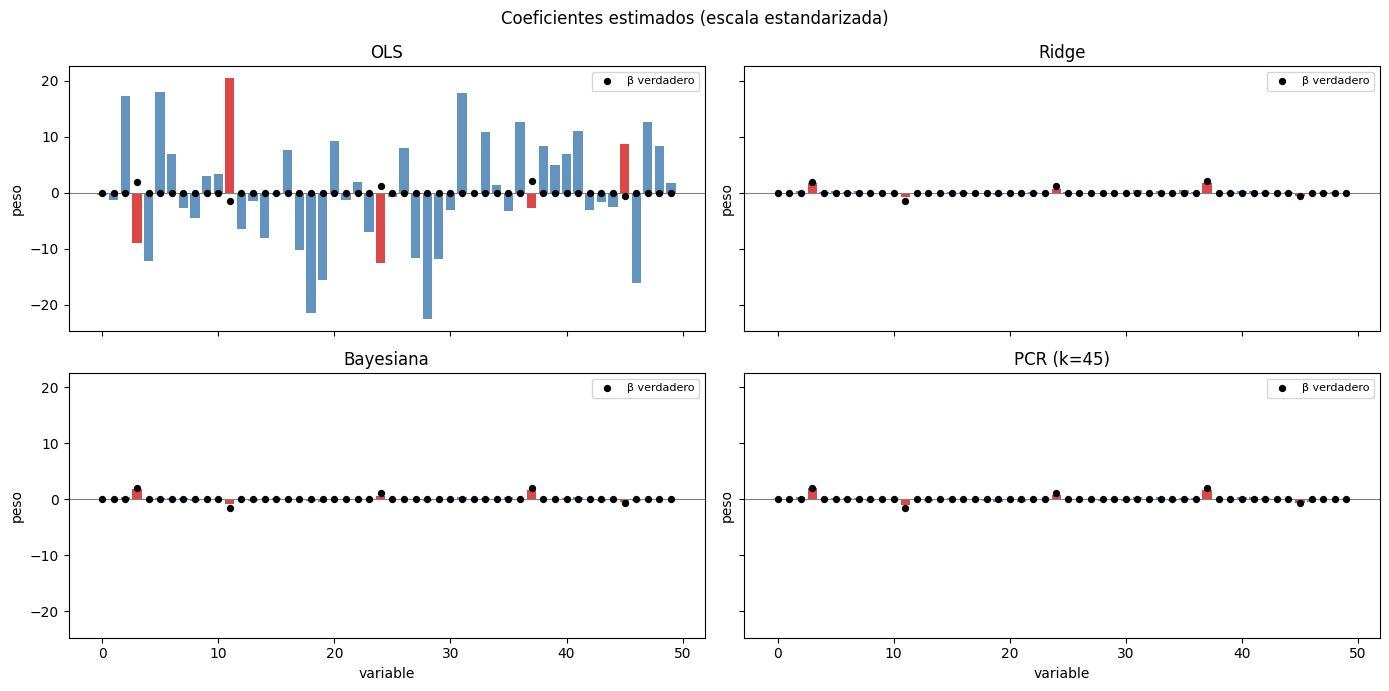

In [19]:
coeficientes = {
    "OLS": ols.coef_,
    "Ridge": ridge.coef_,
    "Bayesiana": bayes.coef_,
    f"PCR (k={k_optimo})": beta_pcr_std,
}

fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True, sharey=True)
eje_x = np.arange(P)

for ax, (nombre, coef) in zip(axes.ravel(), coeficientes.items()):
    colores = np.where(np.isin(eje_x, INFORMATIVAS), "tab:red", "steelblue")
    ax.bar(eje_x, coef, color=colores, alpha=0.85)
    ax.scatter(eje_x, beta_true_std, color="black", s=18, zorder=3, label="β verdadero")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(nombre)
    ax.set_ylabel("peso")
    ax.legend(loc="upper right", fontsize=8)

for ax in axes[1]:
    ax.set_xlabel("variable")
fig.suptitle("Coeficientes estimados (escala estandarizada)")
fig.tight_layout()
plt.show()

In [20]:
# Tabla resumen: magnitud de peso asignada a las variables informativas vs. el resto
filas = []
for nombre, coef in coeficientes.items():
    abs_coef = np.abs(coef)
    filas.append({
        "modelo": nombre,
        "|β| medio (informativas)": abs_coef[INFORMATIVAS].mean(),
        "|β| medio (resto)": np.delete(abs_coef, INFORMATIVAS).mean(),
    })
pd.DataFrame(filas).round(3)

,modelo,|β| medio (informativas),|β| medio (resto)
0,OLS,10.642,7.602
1,Ridge,1.071,0.161
2,Bayesiana,1.090,0.165
3,PCR (k=45),1.206,0.205


In [21]:
MODELO_ELEGIDO = "Ridge"

modelos = {
    "OLS": ols,
    "Ridge": ridge,
    "Bayesiana": bayes,
    "PCR": pcr,
}
modelo = modelos[MODELO_ELEGIDO]
print("Modelo elegido:", MODELO_ELEGIDO)

Modelo elegido: Ridge


## 5. PCA sobre el conjunto de entrenamiento

Se ajusta PCA sobre train (estandarizado) y se grafican las dos primeras componentes.

Es el **mismo ajuste** que usa el PCR: mismos datos, mismo escalado, solo cambia cuántas componentes se retienen.

In [22]:
pca = PCA().fit(X_train_std)
var_ratio = pca.explained_variance_ratio_

print(f"PC1: {var_ratio[0]:.1%} de la varianza")
print(f"PC2: {var_ratio[1]:.1%} de la varianza")
print(f"PC1+PC2: {var_ratio[:2].sum():.1%}")
print(f"componentes para 90% de varianza: {np.searchsorted(np.cumsum(var_ratio), 0.90) + 1}")

PC1: 8.9% de la varianza
PC2: 8.4% de la varianza
PC1+PC2: 17.3%
componentes para 90% de varianza: 23


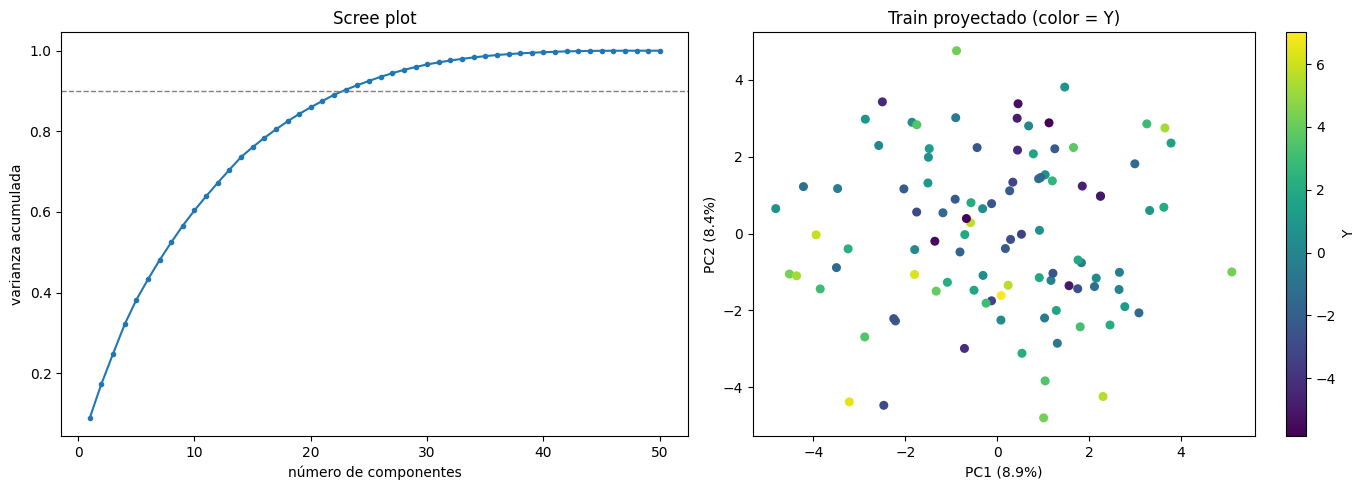

In [23]:
train_pca = pca.transform(X_train_std)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(np.arange(1, P + 1), np.cumsum(var_ratio), marker="o", markersize=3)
axes[0].axhline(0.90, color="gray", linestyle="--", linewidth=1)
axes[0].set_xlabel("número de componentes")
axes[0].set_ylabel("varianza acumulada")
axes[0].set_title("Scree plot")

sc = axes[1].scatter(
    train_pca[:, 0], train_pca[:, 1],
    c=y_train, cmap="viridis", s=30,
)
axes[1].set_xlabel(f"PC1 ({var_ratio[0]:.1%})")
axes[1].set_ylabel(f"PC2 ({var_ratio[1]:.1%})")
axes[1].set_title("Train proyectado (color = Y)")
fig.colorbar(sc, ax=axes[1], label="Y")

fig.tight_layout()
plt.show()

## 6. Construcción del conjunto test desplazado (A) y el original (B)

Se parte el test en dos mitades. Al conjunto A se le suma un vector aleatorio $\delta \sim U(-5, 5)^{50}$
a **todas las filas** (una constante por variable), lo que cambia la media pero no la covarianza.

In [24]:
rng_shift = np.random.default_rng(SEED + 1)

indices = rng_shift.permutation(N_TEST)
indices_A, indices_B = indices[: N_TEST // 2], indices[N_TEST // 2 :]

A = X_test[indices_A].copy()
B = X_test[indices_B].copy()
y_A = y_test[indices_A]
y_B = y_test[indices_B]

delta = rng_shift.uniform(-5, 5, size=P)
A_shift = A + delta  # mismo delta en todas las filas

print(f"A: {A_shift.shape}  |  B: {B.shape}")
print(f"media de delta: {delta.mean():.2f}  |  rango: [{delta.min():.2f}, {delta.max():.2f}]")

A: (25, 50)  |  B: (25, 50)
media de delta: 0.22  |  rango: [-4.96, 4.19]


## 7. Predicción sobre A y B

Se predice con el modelo elegido en el punto 4 (sin re-entrenar ni re-escalar) y se compara el error por observación
y el MSE de cada conjunto.

In [25]:
y_pred_A = modelo.predict(scaler.transform(A_shift))
y_pred_B = modelo.predict(scaler.transform(B))

error_A = y_A - y_pred_A
error_B = y_B - y_pred_B


def resumen_errores(nombre, y_true, y_pred):
    e = y_true - y_pred
    return {
        "conjunto": nombre,
        "MSE": np.mean(e ** 2),
        "sesgo": e.mean(),
        "sesgo²": e.mean() ** 2,
        "varianza": e.var(),
    }


pd.DataFrame([
    resumen_errores("A (desplazado)", y_A, y_pred_A),
    resumen_errores("B (original)", y_B, y_pred_B),
]).round(3)

,conjunto,MSE,sesgo,sesgo²,varianza
0,A (desplazado),51.156,7.112,50.586,0.570
1,B (original),0.290,0.053,0.003,0.288


In [26]:
# Chequeo teórico: como el shift mueve la media, el error esperado en A es -(β_efectivo · δ)
if MODELO_ELEGIDO == "PCR":
    beta_std_modelo = coefs_pcr_en_std(pcr)
else:
    beta_std_modelo = modelo.coef_
beta_efectivo = beta_std_modelo / scaler.scale_

sesgo_teorico = -(beta_efectivo @ delta)
print(f"sesgo teórico  -(β_ef · δ) : {sesgo_teorico:9.3f}")
print(f"sesgo observado en A       : {error_A.mean():9.3f}")
print(f"(β_ef · δ)²                : {sesgo_teorico ** 2:9.3f}")
print(f"MSE(A) - MSE(B)            : {np.mean(error_A ** 2) - np.mean(error_B ** 2):9.3f}")
print()
print(f"(β_true · δ)² (oráculo)    : {(beta_true @ delta) ** 2:.3f}")
print("La diferencia entre β_ef y β_true se amplifica porque δ es grande.")

sesgo teórico  -(β_ef · δ) :     7.257
sesgo observado en A       :     7.112
(β_ef · δ)²                :    52.663
MSE(A) - MSE(B)            :    50.866

(β_true · δ)² (oráculo)    : 15.148
La diferencia entre β_ef y β_true se amplifica porque δ es grande.


## 8. Proyección de A y B en el espacio de componentes principales

Se usa el PCA ajustado en train (misma media y mismas componentes). Colorear por error cuadrático de predicción.

**Importante:** no re-ajustar ni re-centrar el PCA con A y B; si se centra cada conjunto por su propia media,
el desplazamiento desaparece del gráfico.

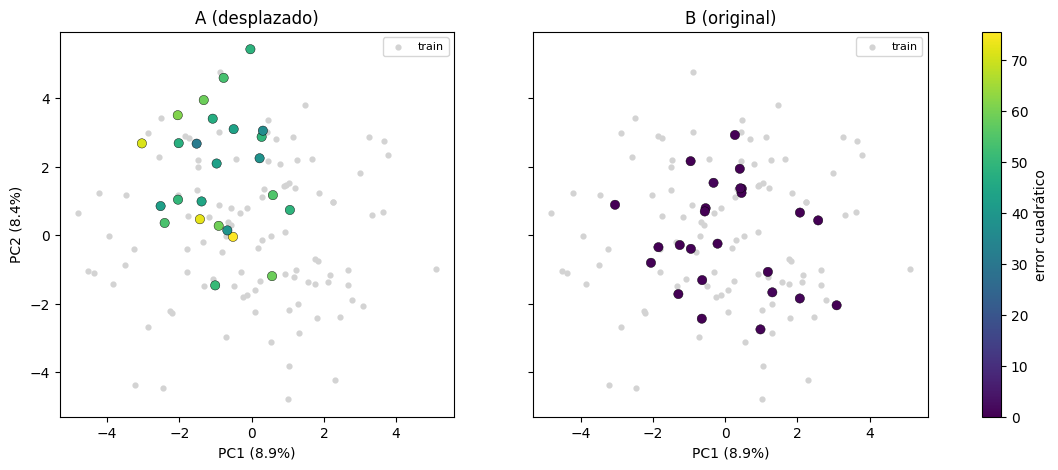

In [27]:
pca_A = pca.transform(scaler.transform(A_shift))
pca_B = pca.transform(scaler.transform(B))

err2_A = error_A ** 2
err2_B = error_B ** 2
vmax = max(err2_A.max(), err2_B.max())

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

for ax, (nombre, proy, err2) in zip(
    axes,
    [("A (desplazado)", pca_A, err2_A), ("B (original)", pca_B, err2_B)],
):
    ax.scatter(train_pca[:, 0], train_pca[:, 1], color="lightgray", s=12, label="train")
    sc = ax.scatter(proy[:, 0], proy[:, 1], c=err2, cmap="viridis", s=45, vmin=0, vmax=vmax, edgecolor="k", linewidth=0.3)
    ax.set_title(nombre)
    ax.set_xlabel(f"PC1 ({var_ratio[0]:.1%})")
    ax.legend(loc="best", fontsize=8)

axes[0].set_ylabel(f"PC2 ({var_ratio[1]:.1%})")
fig.colorbar(sc, ax=axes, label="error cuadrático")
plt.show()

## 9. Estrategia si no se conocen las constantes

In [28]:
# Demostración: estimar el corrimiento como diferencia de medias (A vs. B, sin etiquetas) y corregir
delta_hat = A_shift.mean(axis=0) - B.mean(axis=0)
A_corregido = A_shift - delta_hat

y_pred_A_corr = modelo.predict(scaler.transform(A_corregido))
mse_A = np.mean(error_A ** 2)
mse_A_corr = np.mean((y_A - y_pred_A_corr) ** 2)

print(f"error de estimación de delta (norma): {np.linalg.norm(delta_hat - delta):.3f}")
print(f"MSE(A) sin corregir : {mse_A:.3f}")
print(f"MSE(A) corregido    : {mse_A_corr:.3f}")
print(f"MSE(B) referencia   : {np.mean(error_B ** 2):.3f}")

error de estimación de delta (norma): 1.164
MSE(A) sin corregir : 51.156
MSE(A) corregido    : 1.812
MSE(B) referencia   : 0.290
